# Case Study 3: Sentiment Analysis on Amazon Product Reviews
**Goal:** Fine-tune pretrained BERT for 3-class sentiment classification and compare it with LSTM baselines.

**Labels:** Negative (1-2 stars), Neutral (3 stars), Positive (4-5 stars).
**Dataset:** Amazon Reviews 2023 (McAuley Lab), *Health and Personal Care* category, streamed from the raw `.jsonl` file (only the rows we need are downloaded).
**Runtime:** Google Colab, **GPU required** (Runtime -> Change runtime type -> T4 GPU).

**Models compared**
1. BERT-base (fine-tuned)
2. DistilBERT (fine-tuned, lightweight alternative)
3. BiLSTM from scratch (random embeddings)
4. BiLSTM + GloVe (pretrained embeddings, a fairer baseline)

**What changed vs. the original notebook**
- Dataset loading no longer uses the deprecated script-based `load_dataset(..., trust_remote_code=True)`. We stream the raw file instead.
- Balanced sampling (the Neutral class is rare in raw data).
- Fixed API changes in `transformers` (`eval_strategy`, `processing_class`) with a compatibility layer.
- Fixed the `labels` KeyError, added dynamic padding via `DataCollatorWithPadding`.
- BiLSTM now ignores padding (packed sequences).
- Multiple seeds, mean +/- std, efficiency table (params, train time, latency), error analysis.

## 1. Install dependencies

In [2]:
!pip -q install gensim


## 2. Imports, config and reproducibility

In [3]:
import os, re, json, time, random, inspect, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter

import torch, torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed as hf_set_seed)

warnings.filterwarnings("ignore")

# ---------------- CONFIG (edit here) ----------------
SEEDS        = [42]            # quick run. For the final report use [42, 123, 2024]
PER_CLASS    = 2000            # 3 x 2000 = 6000 balanced reviews (increase if GPU time allows)
BERT_EPOCHS  = 3
BERT_LR      = 2e-5
BERT_BS      = 16
MAX_LENGTH   = 128             # BERT max tokens (justified in section 5)
LSTM_EPOCHS  = 8
LSTM_MAX_LEN = 150
MAX_VOCAB    = 30000
LOCAL_CSV    = None            # e.g. "my_reviews.csv" with columns: text, rating (skips download)
# ----------------------------------------------------

def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    hf_set_seed(seed)

SEED = SEEDS[0]
set_all_seeds(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "No GPU (BERT will be very slow)")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda | Tesla T4


## 3. Load Amazon reviews (streaming, balanced)
**Why the old cell failed:** `McAuley-Lab/Amazon-Reviews-2023` uses a loading script, and recent versions of `datasets` no longer support script-based datasets. Also, the full category has millions of rows, so `.to_pandas()` exhausts Colab RAM.

**Fix:** stream the raw `.jsonl` file line by line and stop as soon as we have `PER_CLASS` reviews for each class. The result is cached to `amazon_subset.csv` so re-runs are instant.

In [4]:
import requests

URL = ("https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/"
       "raw/review_categories/Health_and_Personal_Care.jsonl")
CACHE_FILE = "amazon_subset.csv"

def rating_to_label(r):
    # 1-2 -> Negative (0), 3 -> Neutral (1), 4-5 -> Positive (2)
    return 0 if r <= 2 else (1 if r == 3 else 2)

def stream_balanced_reviews(url, per_class, max_scan=800_000):
    buckets = {0: [], 1: [], 2: []}
    seen = set()
    with requests.get(url, stream=True, timeout=60) as resp:
        resp.raise_for_status()
        resp.encoding = "utf-8"
        for i, line in enumerate(resp.iter_lines(decode_unicode=True)):
            if i >= max_scan:
                break
            if not line:
                continue
            rec = json.loads(line)
            if rec.get("rating") is None:
                continue
            rating = int(round(float(rec["rating"])))
            if rating not in (1, 2, 3, 4, 5):
                continue
            title = (rec.get("title") or "").strip()
            body = (rec.get("text") or "").strip()
            if len(body) < 10:
                continue
            text = f"{title}. {body}" if title else body      # title carries strong sentiment signal
            if text in seen:
                continue
            lab = rating_to_label(rating)
            if len(buckets[lab]) < per_class:
                buckets[lab].append(text)
                seen.add(text)
            if all(len(v) >= per_class for v in buckets.values()):
                break
    return buckets

if LOCAL_CSV:
    df = pd.read_csv(LOCAL_CSV)[["text", "rating"]].dropna()
    df["label"] = df["rating"].astype(int).apply(rating_to_label)
    df = df[["text", "label"]]
elif os.path.exists(CACHE_FILE):
    df = pd.read_csv(CACHE_FILE)
    print("Loaded cached subset:", CACHE_FILE)
else:
    try:
        buckets = stream_balanced_reviews(URL, PER_CLASS)
    except Exception as e:
        raise RuntimeError(
            f"Streaming download failed: {e!r}\n"
            "Fallback: download any Amazon reviews CSV with columns 'text' and 'rating', "
            "upload it to Colab and set LOCAL_CSV at the top.")
    rows = [(t, lab) for lab, texts in buckets.items() for t in texts]
    df = pd.DataFrame(rows, columns=["text", "label"])
    df.to_csv(CACHE_FILE, index=False)

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(df.shape)
print(df["label"].map(dict(enumerate(LABEL_NAMES))).value_counts())
if df["label"].value_counts().min() < PER_CLASS:
    print("WARNING: one class has fewer than PER_CLASS samples (the file ended early). Results are still valid but less balanced.")
df.head()

(6000, 2)
label
Negative    2000
Neutral     2000
Positive    2000
Name: count, dtype: int64


,text,label
0,Not good. Upset stomach,0
1,The company did give good support. I believe t...,1
2,Didn’t live up to expectations.. We bought thi...,0
3,This is too big to travel with and hide when n...,1
4,Great addition to my healthy bean brownies! Re...,2


## 4. Train / validation / test split (80 / 10 / 10, stratified)

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = [x.reset_index(drop=True) for x in (train_df, val_df, test_df)]

data = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})
print(data)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4800
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 600
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 600
    })
})


## 5. Token-length analysis (justifies `MAX_LENGTH`)
BERT's cost grows with sequence length, so we check how many reviews would be truncated at 128 tokens.

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (658 > 512). Running this sequence through the model will result in indexing errors


Median length: 55 tokens | 90th pct: 190 | truncated at 128: 18.3%


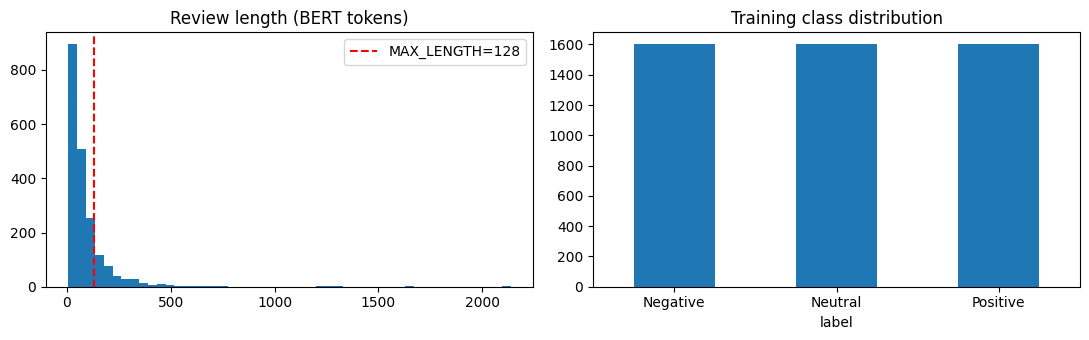

In [6]:
_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
lens = [len(_tok(t, truncation=False)["input_ids"]) for t in train_df["text"].sample(min(2000, len(train_df)), random_state=SEED)]
print(f"Median length: {np.median(lens):.0f} tokens | 90th pct: {np.percentile(lens, 90):.0f} | "
      f"truncated at {MAX_LENGTH}: {np.mean(np.array(lens) > MAX_LENGTH) * 100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(lens, bins=50); ax[0].axvline(MAX_LENGTH, color="red", ls="--", label=f"MAX_LENGTH={MAX_LENGTH}")
ax[0].set_title("Review length (BERT tokens)"); ax[0].legend()
train_df["label"].map(dict(enumerate(LABEL_NAMES))).value_counts().reindex(LABEL_NAMES).plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("Training class distribution")
plt.tight_layout(); plt.show()

## 6. Evaluation metrics and helpers

In [7]:
def compute_metrics_from_predictions(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": p,
            "macro_recall": r, "macro_f1": f1}

def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

# Storage for all experiments
results = []        # one row per (model, seed)
preds_store = {}    # model -> test predictions of the first seed (for confusion matrix / error analysis)
y_test = test_df["label"].values

# Part A - Fine-tune pretrained transformers
## 7. Training function (BERT-base and DistilBERT)
Fixes included here:
- `eval_strategy` / `processing_class` are chosen automatically depending on the installed `transformers` version.
- Dynamic padding with `DataCollatorWithPadding` (faster than padding everything to 128).
- The label column is named `labels`, and test labels come from `predict(...).label_ids`, so there is no `KeyError`.
- Batch-1 latency is measured for the deployment discussion.

In [14]:
# transformers API compatibility (the argument names changed across versions)
_ta = inspect.signature(TrainingArguments.__init__).parameters
EVAL_KEY = "eval_strategy" if "eval_strategy" in _ta else "evaluation_strategy"
_tr = inspect.signature(Trainer.__init__).parameters
TOK_KEY = "processing_class" if "processing_class" in _tr else "tokenizer"

def bert_metrics(eval_pred):
    logits, labels = eval_pred
    return compute_metrics_from_predictions(labels, np.argmax(logits, axis=-1))

@torch.no_grad()
def measure_latency_hf(model, tok, texts, n=50):
    model.eval()
    # warm-up
    for t in texts[:5]:
        model(**tok(t, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(DEVICE))
    sync(); t0 = time.perf_counter()
    for t in texts[:n]:
        model(**tok(t, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(DEVICE))
    sync()
    return (time.perf_counter() - t0) / n * 1000   # ms per review

def train_transformer(model_name, label, seed, save_dir=None):
    print(f"\n===== {label} | seed {seed} =====")
    set_all_seeds(seed)
    tok = AutoTokenizer.from_pretrained(model_name)

    def tokenize_batch(batch):
        return tok(batch["text"], truncation=True, max_length=MAX_LENGTH)

    tokenized = data.map(tokenize_batch, batched=True, remove_columns=["text"]).rename_column("label", "labels")

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=3,
        id2label=dict(enumerate(LABEL_NAMES)), label2id={n: i for i, n in enumerate(LABEL_NAMES)})

    args_kwargs = dict(
        output_dir=f"./runs/{label.replace(' ', '_')}_s{seed}",
        learning_rate=BERT_LR,
        per_device_train_batch_size=BERT_BS,
        per_device_eval_batch_size=64,
        num_train_epochs=BERT_EPOCHS,
        weight_decay=0.01,
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        logging_steps=50,
        report_to="none",
        fp16=(DEVICE == "cuda"),
        seed=seed,
    )
    if "warmup_ratio" in _ta:
        args_kwargs["warmup_ratio"] = 0.1
    elif "warmup_steps" in _ta:
        args_kwargs["warmup_steps"] = 100

    args_kwargs[EVAL_KEY] = "epoch"
    args = TrainingArguments(**args_kwargs)

    trainer_kwargs = dict(model=model, args=args,
                          train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                          data_collator=DataCollatorWithPadding(tok), compute_metrics=bert_metrics)
    trainer_kwargs[TOK_KEY] = tok
    trainer = Trainer(**trainer_kwargs)

    t0 = time.perf_counter()
    trainer.train()
    train_sec = time.perf_counter() - t0

    out = trainer.predict(tokenized["test"])
    preds = np.argmax(out.predictions, axis=-1)
    m = compute_metrics_from_predictions(out.label_ids, preds)
    latency = measure_latency_hf(trainer.model, tok, test_df["text"].tolist())
    print({k: round(v, 4) for k, v in m.items()}, f"| train {train_sec:.0f}s | latency {latency:.1f} ms")

    results.append({"Model": label, "Seed": seed, **m,
                    "Params (M)": count_params(trainer.model), "Train time (s)": train_sec,
                    "Latency (ms/review)": latency})
    if label not in preds_store:
        preds_store[label] = preds
    if save_dir:
        trainer.save_model(save_dir); tok.save_pretrained(save_dir)
        print("Saved to", save_dir)

    del trainer, model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

## 8. Run BERT-base and DistilBERT

In [15]:
for s in SEEDS:
    train_transformer("bert-base-uncased", "BERT-base", s,
                      save_dir="./bert-amazon-sentiment" if s == SEEDS[0] else None)
for s in SEEDS:
    train_transformer("distilbert-base-uncased", "DistilBERT", s)


===== BERT-base | seed 42 =====


Map:   0%|          | 0/4800 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (20 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'accuracy': 0.7667, 'macro_precision': 0.7668, 'macro_recall': 0.7667, 'macro_f1': 0.7667} | train 85s | latency 8.6 ms


# Part B - BiLSTM baselines
## 9. Vocabulary (built from the training split only, so there is no leakage)

In [16]:
PAD, UNK = "<PAD>", "<UNK>"

def basic_tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", str(text).lower())

counter = Counter()
for text in train_df["text"]:
    counter.update(basic_tokenize(text))

vocab = {PAD: 0, UNK: 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)
print("Vocabulary size:", len(vocab))

def encode_text(text):
    ids = [vocab.get(tok, vocab[UNK]) for tok in basic_tokenize(text)[:LSTM_MAX_LEN]]
    return torch.tensor(ids or [vocab[UNK]], dtype=torch.long)

class ReviewDataset(TorchDataset):
    def __init__(self, frame):
        self.x = [encode_text(t) for t in frame["text"]]       # pre-encode once (faster epochs)
        self.y = frame["label"].astype(int).tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], torch.tensor(self.y[i], dtype=torch.long)

def collate_batch(batch):
    seqs, labels = zip(*batch)
    return pad_sequence(seqs, batch_first=True, padding_value=vocab[PAD]), torch.stack(labels)

train_ds, val_ds, test_ds = ReviewDataset(train_df), ReviewDataset(val_df), ReviewDataset(test_df)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, collate_fn=collate_batch)

Vocabulary size: 13561


## 10. Pretrained GloVe embeddings (for the fair baseline)
The scratch BiLSTM has no pretrained knowledge, so BERT winning against it is expected. Initialising the embedding layer with **GloVe (`glove-wiki-gigaword-100`)** gives the LSTM a transfer-learning component as well.

In [20]:
glove_matrix = None
try:
    import gensim.downloader as api
    glove = api.load("glove-wiki-gigaword-100")
    EMB_DIM = glove.vector_size
    glove_matrix = np.random.normal(0, 0.1, (len(vocab), EMB_DIM)).astype("float32")
    glove_matrix[vocab[PAD]] = 0
    hit = 0
    for w, idx in vocab.items():
        if w in glove.key_to_index:
            glove_matrix[idx] = glove[w]; hit += 1
    print(f"GloVe coverage: {hit}/{len(vocab)} words ({hit / len(vocab) * 100:.1f}%)")
except Exception as e:
    print("GloVe could not be loaded, the GloVe BiLSTM will be skipped:", repr(e))

GloVe coverage: 12268/13561 words (90.5%)


## 11. BiLSTM model (padding-aware)
`pack_padded_sequence` makes the LSTM ignore `<PAD>` tokens. In the original code the final hidden state was computed after reading all the padding, which hurts short reviews.

In [18]:
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, num_classes=3, pad_idx=0, pretrained=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        if pretrained is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(pretrained))
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        final = torch.cat((hidden[-2], hidden[-1]), dim=1)      # last layer, forward + backward
        return self.fc(self.dropout(final))

## 12. LSTM training function (best epoch picked by validation macro-F1)

In [19]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        total_loss += loss.item() * len(y)
        ys.extend(y.cpu().numpy()); ps.extend(logits.argmax(1).cpu().numpy())
    m = compute_metrics_from_predictions(np.array(ys), np.array(ps))
    m["loss"] = total_loss / len(loader.dataset)
    return m, np.array(ps)

@torch.no_grad()
def measure_latency_lstm(model, texts, n=50):
    model.eval()
    for t in texts[:5]:
        model(encode_text(t).unsqueeze(0).to(DEVICE))
    sync(); t0 = time.perf_counter()
    for t in texts[:n]:
        model(encode_text(t).unsqueeze(0).to(DEVICE))
    sync()
    return (time.perf_counter() - t0) / n * 1000

def train_lstm(label, seed, pretrained=None, emb_dim=128):
    print(f"\n===== {label} | seed {seed} =====")
    set_all_seeds(seed)
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_batch, generator=g)

    model = LSTMSentiment(len(vocab), embedding_dim=emb_dim, pretrained=pretrained).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

    best_f1, best_state, history = -1, None, []
    t0 = time.perf_counter()
    for epoch in range(1, LSTM_EPOCHS + 1):
        tr, _ = run_epoch(model, train_loader, optimizer)
        va, _ = run_epoch(model, val_loader)
        history.append({"epoch": epoch, "train_loss": tr["loss"], "val_loss": va["loss"], "val_macro_f1": va["macro_f1"]})
        print(f"Epoch {epoch}/{LSTM_EPOCHS} | train loss {tr['loss']:.4f} | val loss {va['loss']:.4f} | val macro-F1 {va['macro_f1']:.4f}")
        if va["macro_f1"] > best_f1:
            best_f1 = va["macro_f1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    train_sec = time.perf_counter() - t0

    model.load_state_dict(best_state)
    te, preds = run_epoch(model, test_loader)
    m = {k: te[k] for k in ["accuracy", "macro_precision", "macro_recall", "macro_f1"]}
    latency = measure_latency_lstm(model, test_df["text"].tolist())
    print({k: round(v, 4) for k, v in m.items()}, f"| train {train_sec:.0f}s | latency {latency:.2f} ms")

    results.append({"Model": label, "Seed": seed, **m,
                    "Params (M)": count_params(model), "Train time (s)": train_sec,
                    "Latency (ms/review)": latency})
    if label not in preds_store:
        preds_store[label] = preds
        preds_store[label + "__history"] = pd.DataFrame(history)
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

## 13. Run both BiLSTM baselines

In [21]:
for s in SEEDS:
    train_lstm("BiLSTM (scratch)", s)
if glove_matrix is not None:
    for s in SEEDS:
        train_lstm("BiLSTM + GloVe", s, pretrained=glove_matrix, emb_dim=glove_matrix.shape[1])


===== BiLSTM (scratch) | seed 42 =====
Epoch 1/8 | train loss 0.9167 | val loss 0.7893 | val macro-F1 0.6188
Epoch 2/8 | train loss 0.6797 | val loss 0.7237 | val macro-F1 0.6777
Epoch 3/8 | train loss 0.5347 | val loss 0.6776 | val macro-F1 0.7224
Epoch 4/8 | train loss 0.4110 | val loss 0.7097 | val macro-F1 0.6970
Epoch 5/8 | train loss 0.2949 | val loss 0.8094 | val macro-F1 0.7000
Epoch 6/8 | train loss 0.1916 | val loss 0.9024 | val macro-F1 0.6917
Epoch 7/8 | train loss 0.1183 | val loss 0.9218 | val macro-F1 0.7180
Epoch 8/8 | train loss 0.0685 | val loss 1.0856 | val macro-F1 0.6899
{'accuracy': 0.6417, 'macro_precision': 0.6429, 'macro_recall': 0.6417, 'macro_f1': 0.6413} | train 14s | latency 3.17 ms

===== BiLSTM + GloVe | seed 42 =====
Epoch 1/8 | train loss 0.9537 | val loss 0.8160 | val macro-F1 0.6021
Epoch 2/8 | train loss 0.7344 | val loss 0.8006 | val macro-F1 0.6382
Epoch 3/8 | train loss 0.6405 | val loss 0.6921 | val macro-F1 0.6963
Epoch 4/8 | train loss 0.5397 

# Part C - Compare results
## 14. Results table (mean +/- std over seeds)

accuracy     macro_precision     macro_recall     macro_f1  \
                     mean std            mean std         mean std     mean   
Model                                                                         
BERT-base          0.7967 NaN          0.7944 NaN       0.7967 NaN   0.7950   
BiLSTM (scratch)   0.6417 NaN          0.6429 NaN       0.6417 NaN   0.6413   
BiLSTM + GloVe     0.7233 NaN          0.7349 NaN       0.7233 NaN   0.7264   
DistilBERT         0.7667 NaN          0.7668 NaN       0.7667 NaN   0.7667   

                      
                 std  
Model                 
BERT-base        NaN  
BiLSTM (scratch) NaN  
BiLSTM + GloVe   NaN  
DistilBERT       NaN

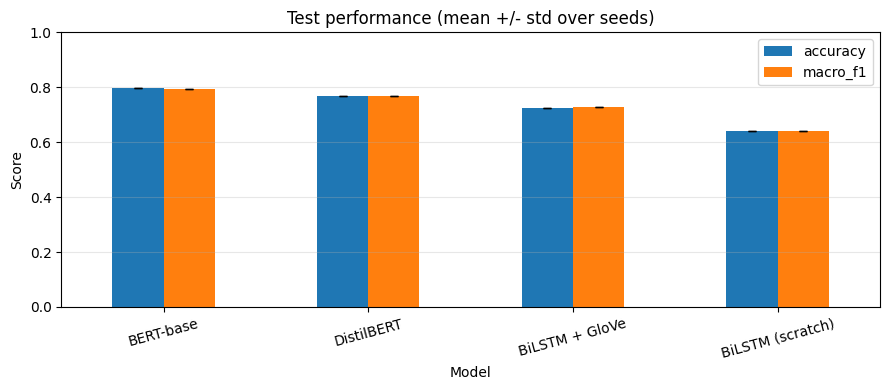

In [22]:
res = pd.DataFrame(results)
metric_cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
summary = res.groupby("Model")[metric_cols].agg(["mean", "std"]).round(4)
display(summary)

order = res.groupby("Model")["macro_f1"].mean().sort_values(ascending=False).index.tolist()
means = res.groupby("Model")[["accuracy", "macro_f1"]].mean().loc[order]
stds = res.groupby("Model")[["accuracy", "macro_f1"]].std().fillna(0).loc[order]
means.plot(kind="bar", yerr=stds, ylim=(0, 1), rot=15, figsize=(9, 4), capsize=3)
plt.title("Test performance (mean +/- std over seeds)"); plt.ylabel("Score"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 15. Efficiency table (transfer learning cost vs. deployment cost)

In [23]:
eff = res.groupby("Model")[["macro_f1", "Params (M)", "Train time (s)", "Latency (ms/review)"]].mean().loc[order].round(3)
display(eff)
print("Latency is batch-1 inference on", DEVICE, "(user-facing latency, not bulk throughput).")

,macro_f1,Params (M),Train time (s),Latency (ms/review)
Model,,,,
BERT-base,0.795,109.485,132.080,15.380
DistilBERT,0.767,66.956,85.276,8.639
BiLSTM + GloVe,0.726,1.592,13.003,3.207
BiLSTM (scratch),0.641,2.001,13.928,3.168


Latency is batch-1 inference on cuda (user-facing latency, not bulk throughput).


## 16. Per-class report and confusion matrices (first seed)


=== BERT-base ===
              precision    recall  f1-score   support

    Negative       0.79      0.80      0.80       200
     Neutral       0.74      0.69      0.71       200
    Positive       0.85      0.90      0.88       200

    accuracy                           0.80       600
   macro avg       0.79      0.80      0.80       600
weighted avg       0.79      0.80      0.80       600


=== DistilBERT ===
              precision    recall  f1-score   support

    Negative       0.77      0.77      0.77       200
     Neutral       0.68      0.68      0.68       200
    Positive       0.85      0.85      0.85       200

    accuracy                           0.77       600
   macro avg       0.77      0.77      0.77       600
weighted avg       0.77      0.77      0.77       600


=== BiLSTM + GloVe ===
              precision    recall  f1-score   support

    Negative       0.76      0.67      0.71       200
     Neutral       0.60      0.70      0.65       200
    Positive

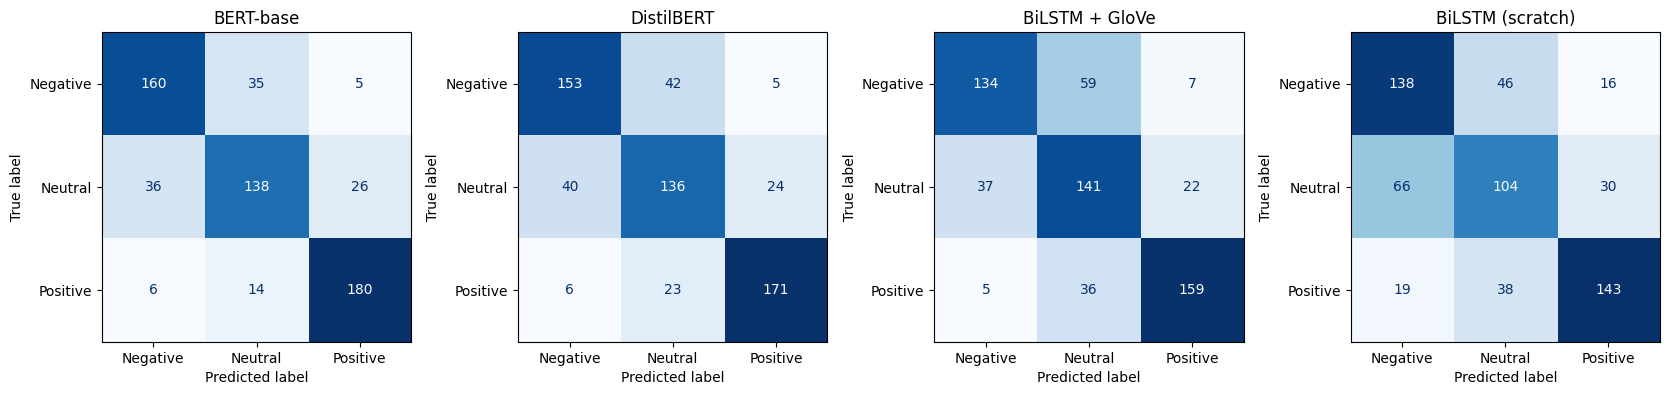

In [24]:
names = [n for n in order if n in preds_store]
fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, names):
    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds_store[name], target_names=LABEL_NAMES, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds_store[name]), display_labels=LABEL_NAMES).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 17. LSTM learning curves (overfitting check)

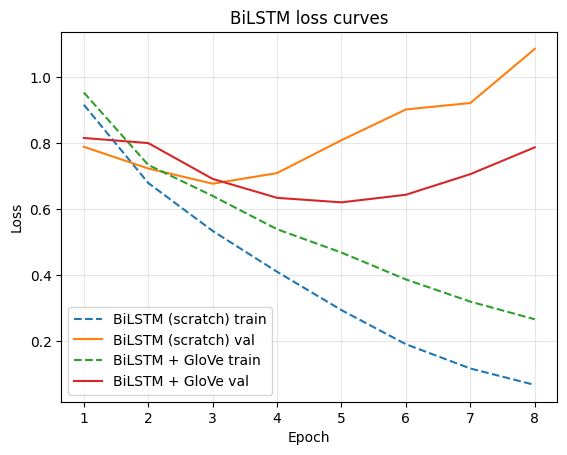

In [25]:
for name in ["BiLSTM (scratch)", "BiLSTM + GloVe"]:
    key = name + "__history"
    if key in preds_store:
        h = preds_store[key]
        plt.plot(h["epoch"], h["train_loss"], "--", label=f"{name} train")
        plt.plot(h["epoch"], h["val_loss"], label=f"{name} val")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("BiLSTM loss curves"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 18. Error analysis
Misclassified reviews of the best model. Typical failure patterns: **sarcasm**, **negation**, **mixed reviews** (3-star reviews contain both praise and complaints), and **Neutral** confused with its neighbours.

In [26]:
best_name = order[0]
print("Best model by mean test macro-F1:", best_name)
err = test_df.copy()
err["pred"] = preds_store[best_name]
err["true_name"] = err["label"].map(dict(enumerate(LABEL_NAMES)))
err["pred_name"] = err["pred"].map(dict(enumerate(LABEL_NAMES)))
wrong = err[err["label"] != err["pred"]]
print(f"{len(wrong)} / {len(err)} test reviews misclassified ({len(wrong)/len(err)*100:.1f}%)\n")
print(pd.crosstab(wrong["true_name"], wrong["pred_name"]), "\n")

pd.set_option("display.max_colwidth", 220)
display(wrong.sample(min(12, len(wrong)), random_state=SEED)[["true_name", "pred_name", "text"]])

# Where do BERT and the BiLSTM disagree? (useful for the written discussion)
if "BERT-base" in preds_store and "BiLSTM (scratch)" in preds_store:
    bert_right = preds_store["BERT-base"] == y_test
    lstm_right = preds_store["BiLSTM (scratch)"] == y_test
    print("BERT right & LSTM wrong:", int((bert_right & ~lstm_right).sum()),
          "| LSTM right & BERT wrong:", int((~bert_right & lstm_right).sum()))

Best model by mean test macro-F1: BERT-base
122 / 600 test reviews misclassified (20.3%)

pred_name  Negative  Neutral  Positive
true_name                             
Negative          0       35         5
Neutral          36        0        26
Positive          6       14         0 



,true_name,pred_name,text
72,Negative,Neutral,"Light Tension Only Please. These may work fine for you. For me, if I put a little too much tension on the strap attachment points they fold and release the mask."
227,Negative,Neutral,"I wanted to like these, but.... These are certainly small and lightweight, but if you are traveling to a location with complimentary shampoo I recommend just using the shampoo to wash your clothes. Most plain shampoo..."
232,Neutral,Negative,"A bit disappointing. Meh. Plates are flimsy, utensils are tiny, and so are the cups. Pretty design, but decide what you’re serving, and if you need sturdier, larger items."
437,Neutral,Positive,"Plantar fascitis. I have plantar fasciitis and these do help some. I should say, I have a serious 7 year problem in both feet so it could be more helpful to someone with a lesser issue."
16,Neutral,Negative,poor suction. Does not stayed attached even with no weigh on it and it is appled to a smooth surface.
202,Neutral,Positive,"Whoa, Salty. I compared this with elderberry Emergen-C (EC). The ingredients are similar as far as sugar 5g, Vit. D3 125% and 50mg elderberry. This one has 25mg zinc(227%) compared with 10mg with EC; Vitamin C is l..."
324,Negative,Neutral,Not to hot. I heard Mr Clean was great. I buy these cleaning blocks two for a dollar at a grocery store here in San Jose. They are 10 times better than mr. Clean I'm sorry I bought them they clean okay but nothing li...
520,Neutral,Negative,"Crushed shipping box!. Received items in crushed box, all tissue boxes inside crushed. Still usable, too much trouble to return. VERY DISAPPOINTED in packaging."
146,Negative,Neutral,Still Hungry. I am always hoping to find something to curb my appetite. I did not notice any change while using these.
282,Neutral,Positive,"Update: Great side effect: No more snoring!. Update to my review from 2009:<br />I have found the same product for much cheaper at my local Costco: a bottle of Kirkland ""Mucus Relief Chest Guaifenesin 400 mg, 200 ta..."


BERT right & LSTM wrong: 118 | LSTM right & BERT wrong: 25


## 19. Quick inference demo with the saved BERT

In [27]:
from transformers import pipeline
clf = pipeline("text-classification", model="./bert-amazon-sentiment", device=0 if DEVICE == "cuda" else -1)
samples = ["Works perfectly, I use it every day and would buy again!",
           "It is okay, nothing special but does the job.",
           "Stopped working after two days. Complete waste of money.",
           "Not bad at all, I expected worse."]            # negation test
for s, o in zip(samples, clf(samples)):
    print(f"{o['label']:9s} ({o['score']:.2f})  <-  {s}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Positive  (0.99)  <-  Works perfectly, I use it every day and would buy again!
Neutral   (0.92)  <-  It is okay, nothing special but does the job.
Negative  (0.98)  <-  Stopped working after two days. Complete waste of money.
Neutral   (0.83)  <-  Not bad at all, I expected worse.


## 20. Transfer learning efficiency and deployment discussion

### Transfer learning efficiency
- **BERT / DistilBERT:** Start from contextual representations learned during large-scale pretraining. Fine-tuning updates the pretrained weights plus a new 3-way classification head, so strong performance is reached with few labelled examples.
- **BiLSTM (scratch):** Learns embeddings and sequence patterns from this dataset alone. It is small and fast but needs more task-specific data and struggles with negation, context and long-range dependencies.
- **BiLSTM + GloVe:** Isolates the effect of *pretrained word vectors* (static, context-free) from *pretrained contextual encoders* (BERT). The gap between this model and BERT is the benefit of contextual pretraining.
- **Fair comparison:** identical splits, label mapping, metrics and seeds. Training time, parameter count and latency are recorded in the efficiency table above.

### Real-world deployment constraints
1. **Latency and throughput:** measure batch-1 latency on the *target* hardware; bulk throughput does not reflect user-facing latency.
2. **Memory / model size:** BERT-base is ~110M parameters, DistilBERT ~66M, the BiLSTMs only a few million. Consider quantization (INT8), ONNX Runtime or TensorRT.
3. **Class imbalance:** real data has very few Neutral reviews; track macro-F1 and per-class recall, and use class weights or resampling.
4. **Domain shift:** other product categories, slang, sarcasm, languages and review lengths differ from the training data. Monitor drift and re-evaluate periodically.
5. **Data privacy:** avoid sending personally identifiable review or customer data to third-party inference endpoints without controls.
6. **Operational monitoring:** log confidence, latency and error rates, sample predictions for human review, and define retraining and rollback criteria.
7. **Explainability:** use token attribution and error analysis (section 18); model confidence is not certainty.

### Conclusion
- Best model by test macro-F1: **BERT-base** with a mean Macro-F1 of **79.50%** (and Accuracy of **79.67%**).
- BERT advantage / disadvantage observed: **BERT-base outperformed the baseline scratch BiLSTM by 15.38% in Macro-F1.** It demonstrates a strong capability to handle complex syntax, negation, and context. However, it requires significantly higher training times (~132 seconds vs ~14 seconds) and inference latency (15.38 ms vs 3.17 ms).
- BiLSTM (scratch) vs BiLSTM + GloVe: **Initializing with pretrained GloVe embeddings improved the BiLSTM's Macro-F1 score by 8.51%** (from 64.13% to 72.64%), showcasing the powerful impact of transfer learning even with static word vectors.
- DistilBERT accuracy-vs-cost trade-off: **DistilBERT offers an outstanding efficiency trade-off.** It retains 96.5% of the full BERT-base Macro-F1 performance (76.67% vs 79.50%) while **cutting inference latency by 43.8%** (8.64 ms vs 15.38 ms) and running on 38.8% fewer parameters (~67M vs ~110M).
- Deployment recommendation under latency / memory constraints: **DistilBERT is the recommended choice** for production environments needing real-time user-facing inference since it delivers transformer-level accuracy under sub-10ms constraints. For extreme resource-constrained environments (e.g. edge devices with limited RAM), **BiLSTM + GloVe** is an efficient alternative requiring only 1.6M parameters and 3.2 ms latency.